In [9]:
from langgraph.graph import StateGraph, START,END
from langchain_google_genai import ChatGoogleGenerativeAI
from typing import TypedDict
from dotenv import load_dotenv

In [10]:
load_dotenv()

True

In [11]:
model=ChatGoogleGenerativeAI(model="gemini-3.6-flash")
model.invoke("hey you there?")

AIMessage(content=[{'type': 'text', 'text': "Hey! Yes, I'm here. How can I help you today?", 'extras': {'signature': 'EpoHCpcHAWkUfRM1JnAc6ZACBRNjftjBtuubSscrQ38y9u3RC9dx8JneGWjHR8zb7CVekAcYrvhQ7d0i8HkyccWkPVWy9bsgsINgqthHjBQ5KeZ8uZgSgYPwCU0S+sjC8K8ZyCZRIG55ZKvMVpiv64C3bOSJXqBTuidAG8KlH4X0tF2d2hW/k7LjMbVzovmoCgQZ/af8wotA5Y1zGGx6an7WARWFjM4GbC+srvQuoO16cJITuWUpmJCCueCCtD/sN3KQIY0B2awz44P41JQWm1yl9xAyjtS/QGDnGnh0XE+FUHESc5Iyvt+He1EvlZ9EhyHf6DqOyD+XyluI5Yt8IPNKRMrS5x6p95oQCb5HT0AL53QT2VtzO53qKaOcmyZ55G1bWNEP+otCHgQ4jE4sYU324Ec2RlQDQuhsrJHWhMuKVT/rrSfRblqj03YkQyBRKMPREmLQtrt8ACQEz79oUt3b2Opz6GSXdozAs+bgBzyMGO6eDpISh6AirKakucTdU0MWiButkUw80OpwKvDcDgndR0MQERPFgtkcxbYEpxjA1VuAbZVhuG3Dm6qQcZHmxl3Nmu5TIyfHK2Da5F7BjmRfvCoXfd+lq6XVgldZIu9vFwey2bFAkwZ8VAuImeg60naq9i1QxxorA+e39u1fKaAxi9hYcRA1FdsO7cfN5OTinP137CUvT0tLWvoPzjU/7HoUcVV+H7RRHJOU4lG4Ueg4m6sulxjRweBV0gDX9fgM2Z92LqActJiQWG5ZQ8F8hwIvBmqiUwBmO7cjA1bV9rpIo9oH0he5+gBcv+WJDbFxmb1DTkBYCJVEz/1JyV7aqeZp0AmwGZy+2IODYuEVO851CqVRT93qILAowQ6fuYgnVb5l9s

In [12]:
class BlogState(TypedDict):
    topic:str
    outline:str
    blog:str
    score:str

In [13]:
# functions
def create_outline(state:BlogState)->BlogState:
    topic=state['topic']
    prompt=f"Create a detailed outline to write a blog on this topic{topic}"
    outline=model.invoke(prompt)
    state['outline']=outline
    return state

def write_blog(state:BlogState)->BlogState:
    outline=state['outline']
    prompt=f"write a detailed bog following this {outline}."
    blog=model.invoke(prompt)
    state['blog']=blog
    return state
def evaluate_blog(state:BlogState)->BlogState:
    blog=state['blog']
    prompt=f"now act as an blog grader and grade this essay {blog} out of 10"
    score=model.invoke(prompt)
    state['score']=score
    return state


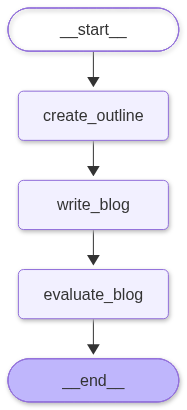

In [14]:
graph=StateGraph(BlogState)
# add nodes
graph.add_node('create_outline',create_outline)
graph.add_node('write_blog',write_blog)
graph.add_node('evaluate_blog',evaluate_blog)

# add edge
graph.add_edge(START,'create_outline')
graph.add_edge('create_outline','write_blog')
graph.add_edge('write_blog','evaluate_blog')
graph.add_edge('evaluate_blog',END)
workflow=graph.compile()
workflow


In [ ]:
initial_state={'topic':"Effects of climate change on Gilgit Baltistan"}
output=workflow.invoke(initial_state)
output